# Notebook 05 · Módulo 4: Reglas de frecuencia (bradicardia y taquicardia)

**Proyecto #7 · Detección de arritmias en tiempo real con TinyML**

**Pregunta:** ¿el corazón va **demasiado lento** (bradicardia) o **demasiado rápido** (taquicardia) **de forma sostenida**?

Aquí **no hay red neuronal ni kNN**: la frecuencia cardiaca se **calcula** a partir de los R–R y se compara contra umbrales. Una regla es transparente, no necesita entrenamiento y cabe de sobra en el Arduino. Lo difícil no es la regla, sino las tres decisiones que señaló tu doctora:

1. **Umbrales**: ¿a partir de cuántos latidos por minuto (lpm)?
2. **Duración**: ¿cuánto tiempo seguido fuera de rango antes de avisar?
3. **Artefactos**: ¿qué hacer con R–R imposibles causados por ruido o por un latido que el detector no vio?

| | En este módulo |
|---|---|
| **Etiquetas** | Episodios calculados con los R **anotados** (referencia) y ritmos anotados por cardiólogos (`SBR`, `SVTA`, `VT`...) |
| **Métricas** | Sensibilidad y PPV **por episodio**, y **falsas alarmas por hora** |
| **Validación** | Los 48 registros de MIT-BIH + Noise Stress Test |

In [1]:
%pip install -q wfdb numpy pandas scipy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import shutil

if not Path("ecg_comun.py").exists():
    entradas = Path("/kaggle/input")
    encontrados = list(entradas.rglob("ecg_comun.py")) if entradas.exists() else []
    if not encontrados:
        raise FileNotFoundError("No encuentro ecg_comun.py: agrégalo con Add Input (el dataset donde lo subiste)")
    shutil.copy(encontrados[0], "ecg_comun.py")
    print("✓ ecg_comun.py copiado desde", encontrados[0])
else:
    print("✓ ecg_comun.py ya está junto al notebook")


✓ ecg_comun.py copiado desde /kaggle/input/datasets/lourdesgarcagarfias/cinc2017-proyecto7/cinc2017-proyecto7/ecg_comun.py


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from IPython.display import display

import ecg_comun as ec

DATOS = Path("datos")
plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True
ec.descargar_base("mitdb", DATOS / "mitdb")
NST = [f"{b}e{snr}" for b in ("118", "119") for snr in ("24", "18", "12", "06", "00", "_6")]
ec.descargar_base("nstdb", DATOS / "nstdb", registros=NST)

Descargando mitdb en datos/mitdb (puede tardar varios minutos)...
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Genera

## 1. Decisiones de este notebook

Estos valores son un **punto de partida**; tú debes justificarlos con literatura (por ejemplo, guías de la AHA/ESC para adultos en reposo).

In [4]:
UMBRAL_BRADI = 60       # lpm: por debajo es bradicardia
UMBRAL_TAQUI = 100      # lpm: por encima es taquicardia
DURACION_MIN_S = 10     # segundos seguidos fuera de rango antes de avisar
N_MEDIANA = 8           # la frecuencia se calcula con la MEDIANA de los últimos 8 R–R (ignora un R–R raro)
RR_MIN, RR_MAX = 0.20, 3.0   # R–R fuera de este rango (s) = artefacto, se ignora (300 lpm y 20 lpm)
MAX_HUECO_S = 3.0       # si pasan más de 3 s sin latidos válidos, se "corta" el episodio

## 2. Las funciones

**Paso 1 · Frecuencia suavizada.** De cada R–R válido sale una frecuencia instantánea (60 / R–R). Pero un solo R–R puede estar mal (una extrasístole, un latido no detectado), así que usamos la **mediana de los últimos 8**. La mediana **solo mira al pasado**: se puede calcular en tiempo real.

**Paso 2 · Episodios.** Un episodio de bradicardia empieza cuando la frecuencia baja de 60 y dura mientras siga abajo. Solo cuenta si dura al menos `DURACION_MIN_S`. La **alarma** sonaría `DURACION_MIN_S` segundos después de que empezó.

In [5]:
def frecuencia_suavizada(r, fs):
    t = r[1:] / fs
    rr = np.diff(r) / fs
    valido = (rr >= RR_MIN) & (rr <= RR_MAX)
    mediana = pd.Series(rr[valido]).rolling(N_MEDIANA, min_periods=max(1, N_MEDIANA // 2)).median()
    return t[valido], 60 / mediana.to_numpy()


def detectar_episodios(t, fc):
    episodios = []
    for tipo, fuera in [("bradi", fc < UMBRAL_BRADI), ("taqui", fc > UMBRAL_TAQUI)]:
        i = 0
        while i < len(t):
            if not fuera[i]:
                i += 1; continue
            j = i
            while j + 1 < len(t) and fuera[j + 1] and t[j + 1] - t[j] <= MAX_HUECO_S:
                j += 1
            if t[j] - t[i] >= DURACION_MIN_S:
                episodios.append({"tipo": tipo, "inicio_s": t[i], "fin_s": t[j],
                                  "alarma_s": t[i] + DURACION_MIN_S})
            i = j + 1
    return pd.DataFrame(episodios, columns=["tipo", "inicio_s", "fin_s", "alarma_s"])


def comparar_episodios(ref, det):
    # Un episodio "coincide" si hay otro del mismo tipo que se traslapa en el tiempo
    def traslapa(e, otros):
        o = otros[otros.tipo == e.tipo]
        return bool(((o.inicio_s <= e.fin_s) & (o.fin_s >= e.inicio_s)).any())
    encontrados = sum(traslapa(e, det) for e in ref.itertuples())
    verdaderos = sum(traslapa(e, ref) for e in det.itertuples())
    return {"ep_ref": len(ref), "ep_det": len(det), "encontrados": encontrados,
            "falsas_alarmas": len(det) - verdaderos}

## 3. Un ejemplo

Buscamos el registro de MIT-BIH donde los cardiólogos anotaron más **bradicardia sinusal** (`SBR`) y graficamos su frecuencia durante los 30 minutos.

Registro de ejemplo: 232 (30.1 min anotados como SBR)


,tipo,inicio_s,fin_s,alarma_s


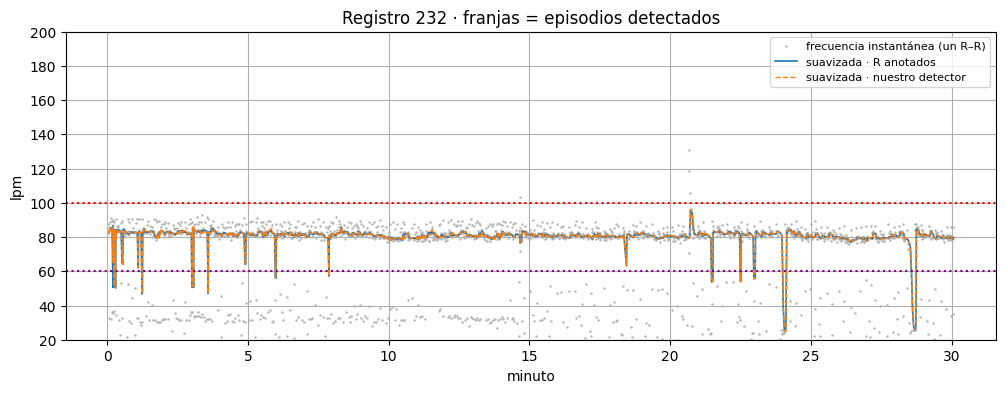

In [6]:
def minutos_de(etiqueta, nombre):
    largo = wfdb.rdheader(str(DATOS / "mitdb" / nombre)).sig_len
    return sum(f - i for i, f, e in ec.leer_ritmos(DATOS / "mitdb", nombre, largo) if e == etiqueta) / ec.FS / 60

registros = ec.listar_registros(DATOS / "mitdb")
ejemplo = max(registros, key=lambda n: minutos_de("SBR", n))
print(f"Registro de ejemplo: {ejemplo} ({minutos_de('SBR', ejemplo):.1f} min anotados como SBR)")

senal, fs, _ = ec.leer_senal(DATOS / "mitdb", ejemplo)
r_ref, _ = ec.leer_latidos(DATOS / "mitdb", ejemplo)
r_det = ec.detectar_picos_r(senal, fs)
t_ref, fc_ref = frecuencia_suavizada(r_ref, fs)
t_det, fc_det = frecuencia_suavizada(r_det, fs)
episodios = detectar_episodios(t_det, fc_det)
display(episodios.round(1))

plt.figure(figsize=(12, 4))
plt.plot(t_ref / 60, 60 / np.diff(r_ref / fs)[np.isin(r_ref[1:] / fs, t_ref)], ".", ms=1.5, color="0.7",
         label="frecuencia instantánea (un R–R)")
plt.plot(t_ref / 60, fc_ref, color="tab:blue", lw=1.2, label="suavizada · R anotados")
plt.plot(t_det / 60, fc_det, color="tab:orange", lw=1, ls="--", label="suavizada · nuestro detector")
plt.axhline(UMBRAL_BRADI, color="purple", ls=":"); plt.axhline(UMBRAL_TAQUI, color="red", ls=":")
for e in episodios.itertuples():
    plt.axvspan(e.inicio_s / 60, e.fin_s / 60, color="purple" if e.tipo == "bradi" else "red", alpha=0.15)
plt.ylim(20, 200); plt.xlabel("minuto"); plt.ylabel("lpm"); plt.legend(loc="upper right", fontsize=8)
plt.title(f"Registro {ejemplo} · franjas = episodios detectados")
plt.show()

**Cómo leerlo:** los puntos grises son la frecuencia de **cada** R–R: brincan mucho (extrasístoles, pausas). La línea azul (mediana de 8) es mucho más estable. Si la naranja (con **nuestro detector**) sigue a la azul (con los R **anotados**), el detector de R es suficientemente bueno para esta tarea.

## 4. Evaluación en los 48 registros

Comparamos los episodios encontrados con **nuestro detector** contra los episodios encontrados con los R **anotados** (la referencia).

In [7]:
filas, todos_ref = [], {}
for nombre in registros:
    x, fs_r, _ = ec.leer_senal(DATOS / "mitdb", nombre)
    r_ref, _ = ec.leer_latidos(DATOS / "mitdb", nombre)
    ref = detectar_episodios(*frecuencia_suavizada(r_ref, fs_r))
    det = detectar_episodios(*frecuencia_suavizada(ec.detectar_picos_r(x, fs_r), fs_r))
    todos_ref[nombre] = ref
    filas.append({"registro": nombre, "horas": len(x) / fs_r / 3600, **comparar_episodios(ref, det)})
tabla_ep = pd.DataFrame(filas)
display(tabla_ep[tabla_ep.ep_ref + tabla_ep.ep_det > 0])

tot = tabla_ep.sum(numeric_only=True)
print(f"Episodios de referencia: {int(tot.ep_ref)} · encontrados por el detector: {int(tot.encontrados)} "
      f"→ Se por episodio = {100 * tot.encontrados / max(tot.ep_ref, 1):.1f} %")
print(f"Falsas alarmas: {int(tot.falsas_alarmas)} en {tot.horas:.1f} h → {tot.falsas_alarmas / tot.horas:.2f} por hora")

,registro,horas,ep_ref,ep_det,encontrados,falsas_alarmas
1,101,0.501543,17,17,17,0
5,105,0.501543,0,1,0,1
6,106,0.501543,11,11,11,0
8,108,0.501543,8,9,6,1
12,113,0.501543,27,27,27,0
13,114,0.501543,2,2,2,0
14,115,0.501543,6,6,6,0
16,117,0.501543,2,2,2,0
19,121,0.501543,16,16,16,0
21,123,0.501543,12,10,12,0


Episodios de referencia: 236 · encontrados por el detector: 230 → Se por episodio = 97.5 %
Falsas alarmas: 18 en 24.1 h → 0.75 por hora


## 5. ¿Coincide con lo que anotaron los cardiólogos?

MIT-BIH trae ritmos anotados. Para cada uno calculamos qué porcentaje de su tiempo quedó dentro de un episodio de **bradi** o de **taqui** según nuestra regla (con los R anotados). Esperamos, por ejemplo, que `SBR` (bradicardia sinusal) salga mayormente como **bradi** y que `SVTA` y `VT` salgan como **taqui**.

In [8]:
tiempo = {}
for nombre in registros:
    largo = wfdb.rdheader(str(DATOS / "mitdb" / nombre)).sig_len
    segundos = np.full(int(largo / ec.FS) + 1, "normal", dtype=object)
    for e in todos_ref[nombre].itertuples():
        segundos[int(e.inicio_s): int(e.fin_s) + 1] = e.tipo
    for ini, fin, et in ec.leer_ritmos(DATOS / "mitdb", nombre, largo):
        tramo = segundos[int(ini / ec.FS): int(fin / ec.FS)]
        d = tiempo.setdefault(et, {"normal": 0, "bradi": 0, "taqui": 0})
        for clase in d:
            d[clase] += int(np.sum(tramo == clase))
tabla_ritmos = pd.DataFrame(tiempo).T
segundos_totales = tabla_ritmos.sum(axis=1)
for c in ["normal", "bradi", "taqui"]:
    tabla_ritmos[c] = (100 * tabla_ritmos[c] / segundos_totales).round(1)
tabla_ritmos["minutos"] = (segundos_totales / 60).round(1)
display(tabla_ritmos.sort_values("minutos", ascending=False).rename(
    columns={"normal": "% normal", "bradi": "% bradi", "taqui": "% taqui"}))

,% normal,% bradi,% taqui,minutos
N,73.3,18.0,8.7,1055.3
AFIB,96.1,0.0,3.9,132.6
P,100.0,0.0,0.0,110.2
B,94.8,1.3,3.9,41.8
SBR,100.0,0.0,0.0,30.1
T,57.0,36.7,6.3,19.0
AFL,70.9,0.0,29.1,13.0
PREX,100.0,0.0,0.0,12.3
BII,4.1,95.9,0.0,11.7
NOD,91.5,4.2,4.2,4.7


**Cómo leerlo:** cada fila es un ritmo anotado por cardiólogos y las columnas dicen qué hizo tu regla en ese tiempo. Que `AFIB` salga a veces como **taqui** no es un error: la FA muchas veces va **rápida**, y en tu sistema el módulo de FA y el de taquicardia pueden avisar **a la vez**.

## 6. Prueba de estrés: falsas alarmas con ruido

En el Noise Stress Test, la verdad viene de las anotaciones (que no tienen ruido) y el detector trabaja sobre la señal **con** ruido. Contamos cuántas alarmas falsas aparecen por hora.

,registro,SNR (dB),falsas alarmas,por hora
0,118e24,24,0,0.0
1,118e18,18,0,0.0
2,118e12,12,0,0.0
3,118e06,6,14,27.9
4,118e00,0,24,47.9
5,118e_6,-6,21,41.9
6,119e24,24,0,0.0
7,119e18,18,0,0.0
8,119e12,12,3,6.0
9,119e06,6,15,29.9


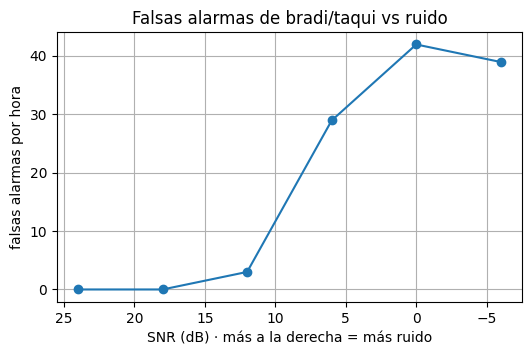

In [9]:
# Detectamos los R de cada registro con ruido UNA vez y los guardamos (para no repetir en la sección 7)
r_nst = {}
for nombre in NST:
    x, fs_nst, _ = ec.leer_senal(DATOS / "nstdb", nombre, canal=0)
    r_nst[nombre] = (ec.leer_latidos(DATOS / "nstdb", nombre)[0], ec.detectar_picos_r(x, fs_nst), len(x) / fs_nst / 3600)

def falsas_alarmas_nst():
    filas = []
    for nombre in NST:
        r_ref, r_det, horas = r_nst[nombre]
        ref = detectar_episodios(*frecuencia_suavizada(r_ref, fs_nst))
        det = detectar_episodios(*frecuencia_suavizada(r_det, fs_nst))
        c = comparar_episodios(ref, det)
        filas.append({"registro": nombre, "SNR (dB)": int(nombre[4:].replace("_", "-")),
                      "falsas alarmas": c["falsas_alarmas"], "por hora": round(c["falsas_alarmas"] / horas, 1)})
    return pd.DataFrame(filas)

tabla_nst = falsas_alarmas_nst()
display(tabla_nst)
resumen = tabla_nst.groupby("SNR (dB)")["por hora"].mean().sort_index(ascending=False)
plt.figure(figsize=(6, 3.5))
plt.plot(resumen.index, resumen.values, "o-")
plt.gca().invert_xaxis()
plt.xlabel("SNR (dB) · más a la derecha = más ruido"); plt.ylabel("falsas alarmas por hora")
plt.title("Falsas alarmas de bradi/taqui vs ruido"); plt.show()

## 7. ¿Cómo cambian las falsas alarmas con tus decisiones?

Probamos varias combinaciones de **duración mínima** y **tamaño de la mediana** sobre los registros con ruido. Es el compromiso clásico: **esperar más** = menos falsas alarmas, pero **avisar más tarde** y perder episodios cortos.

In [10]:
guardado = (DURACION_MIN_S, N_MEDIANA)
r_mitdb = {n: ec.leer_latidos(DATOS / "mitdb", n)[0] for n in registros}
filas = []
for N_MEDIANA in [1, 4, 8]:
    for DURACION_MIN_S in [0, 5, 10, 30]:
        nst = falsas_alarmas_nst()
        ep_mitdb = sum(len(detectar_episodios(*frecuencia_suavizada(r, ec.FS))) for r in r_mitdb.values())
        filas.append({"mediana de": N_MEDIANA, "duración mín (s)": DURACION_MIN_S,
                      "falsas alarmas/h (con ruido)": round(nst["por hora"].mean(), 1),
                      "episodios en MIT-BIH (referencia)": ep_mitdb})
DURACION_MIN_S, N_MEDIANA = guardado
display(pd.DataFrame(filas).pivot(index="mediana de", columns="duración mín (s)",
                                  values="falsas alarmas/h (con ruido)"))
display(pd.DataFrame(filas).pivot(index="mediana de", columns="duración mín (s)",
                                  values="episodios en MIT-BIH (referencia)"))

duración mín (s),0,5,10,30
mediana de,,,,
1,1147.0,2.7,0.0,0.0
4,238.1,32.1,19.8,3.0
8,101.5,26.1,18.8,5.8


duración mín (s),0,5,10,30
mediana de,,,,
1,12426,541,292,89
4,3073,469,240,99
8,1523,434,236,97


**Cómo leerlo:** en la primera tabla quieres números **bajos** (pocas falsas alarmas). En la segunda, fíjate cuántos episodios reales **dejas de ver** cuando exiges más duración. Tu elección final debe equilibrar las dos cosas y **justificarse** (por ejemplo: "un episodio de menos de 10 s no tiene importancia clínica para este dispositivo").

---